In [15]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [16]:
imagem_original = data.camera()

In [17]:
imagem = imagem_original[::2, ::2]

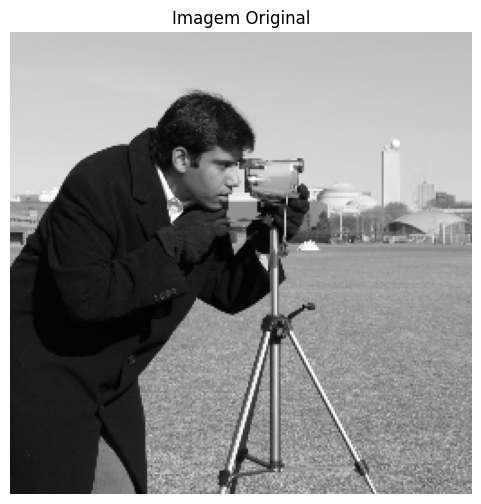

In [18]:
plt.figure(figsize=(6, 6))
plt.imshow(imagem, cmap='gray')
plt.title("Imagem Original")
plt.axis('off')
plt.show()

In [19]:
print("Dimensões da imagem:", imagem.shape)

Dimensões da imagem: (256, 256)


In [20]:
def convolucao_manual(imagem, kernel):
    imagem = np.asarray(imagem, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")

    if kernel.ndim != 2:
        raise ValueError("O kernel deve ser bidimensional.")

    altura_kernel, largura_kernel = kernel.shape

    if altura_kernel % 2 == 0 or largura_kernel % 2 == 0:
        raise ValueError("O kernel deve possuir dimensões ímpares.")

    altura, largura = imagem.shape

    # Calculando o preenchimento necessário nas bordas
    pad_altura = altura_kernel // 2
    pad_largura = largura_kernel // 2

    # Aplicando padding
    imagem_pad = np.pad(
        imagem,
        ((pad_altura, pad_altura),
         (pad_largura, pad_largura)),
        mode='reflect'
    )

    # Invertendo o kernel para realizar a convolução matemática
    kernel = np.flip(kernel, axis=(0, 1))

    # Inicializando a imagem de saída
    resultado = np.zeros((altura, largura), dtype=np.float64)

    # Percorrendo manualmente os elementos do kernel
    for i in range(altura_kernel):
        for j in range(largura_kernel):

            resultado += (
                kernel[i, j] *
                imagem_pad[i:i + altura, j:j + largura]
            )

    return resultado

In [21]:
def filtro_media(imagem, tamanho=3):
    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser positivo e ímpar.")

    kernel = np.ones((tamanho, tamanho), dtype=np.float64)

    kernel /= (tamanho * tamanho)

    resultado = convolucao_manual(imagem, kernel)

    resultado = np.clip(np.rint(resultado), 0, 255).astype(np.uint8)

    return resultado

In [22]:
def filtro_mediana(imagem, tamanho=3):
    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser positivo e ímpar.")

    imagem = np.asarray(imagem)

    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")

    altura, largura = imagem.shape
    pad = tamanho // 2

    imagem_pad = np.pad(
        imagem,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):

            janela = imagem_pad[i:i + tamanho, j:j + tamanho]

            resultado[i, j] = np.median(janela)

    return resultado

In [23]:
def filtro_maximo(imagem, tamanho=3):
    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser positivo e ímpar.")

    imagem = np.asarray(imagem)

    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")

    altura, largura = imagem.shape
    pad = tamanho // 2

    imagem_pad = np.pad(
        imagem,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):

            janela = imagem_pad[i:i + tamanho, j:j + tamanho]

            resultado[i, j] = np.max(janela)

    return resultado

In [24]:
from scipy import stats

def filtro_moda(imagem, tamanho=3):
    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser positivo e ímpar.")

    imagem = np.asarray(imagem)
    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")

    altura, largura = imagem.shape
    pad = tamanho // 2

    imagem_pad = np.pad(
        imagem,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):
            janela = imagem_pad[i:i + tamanho, j:j + tamanho]
            moda_val = stats.mode(janela, axis=None, keepdims=False)[0]
            resultado[i, j] = moda_val

    return resultado

tamanho_janela = 3

imagem_media = filtro_media(imagem, tamanho_janela)
imagem_mediana = filtro_mediana(imagem, tamanho_janela)
imagem_moda = filtro_moda(imagem, tamanho_janela)
imagem_maximo = filtro_maximo(imagem, tamanho_janela)

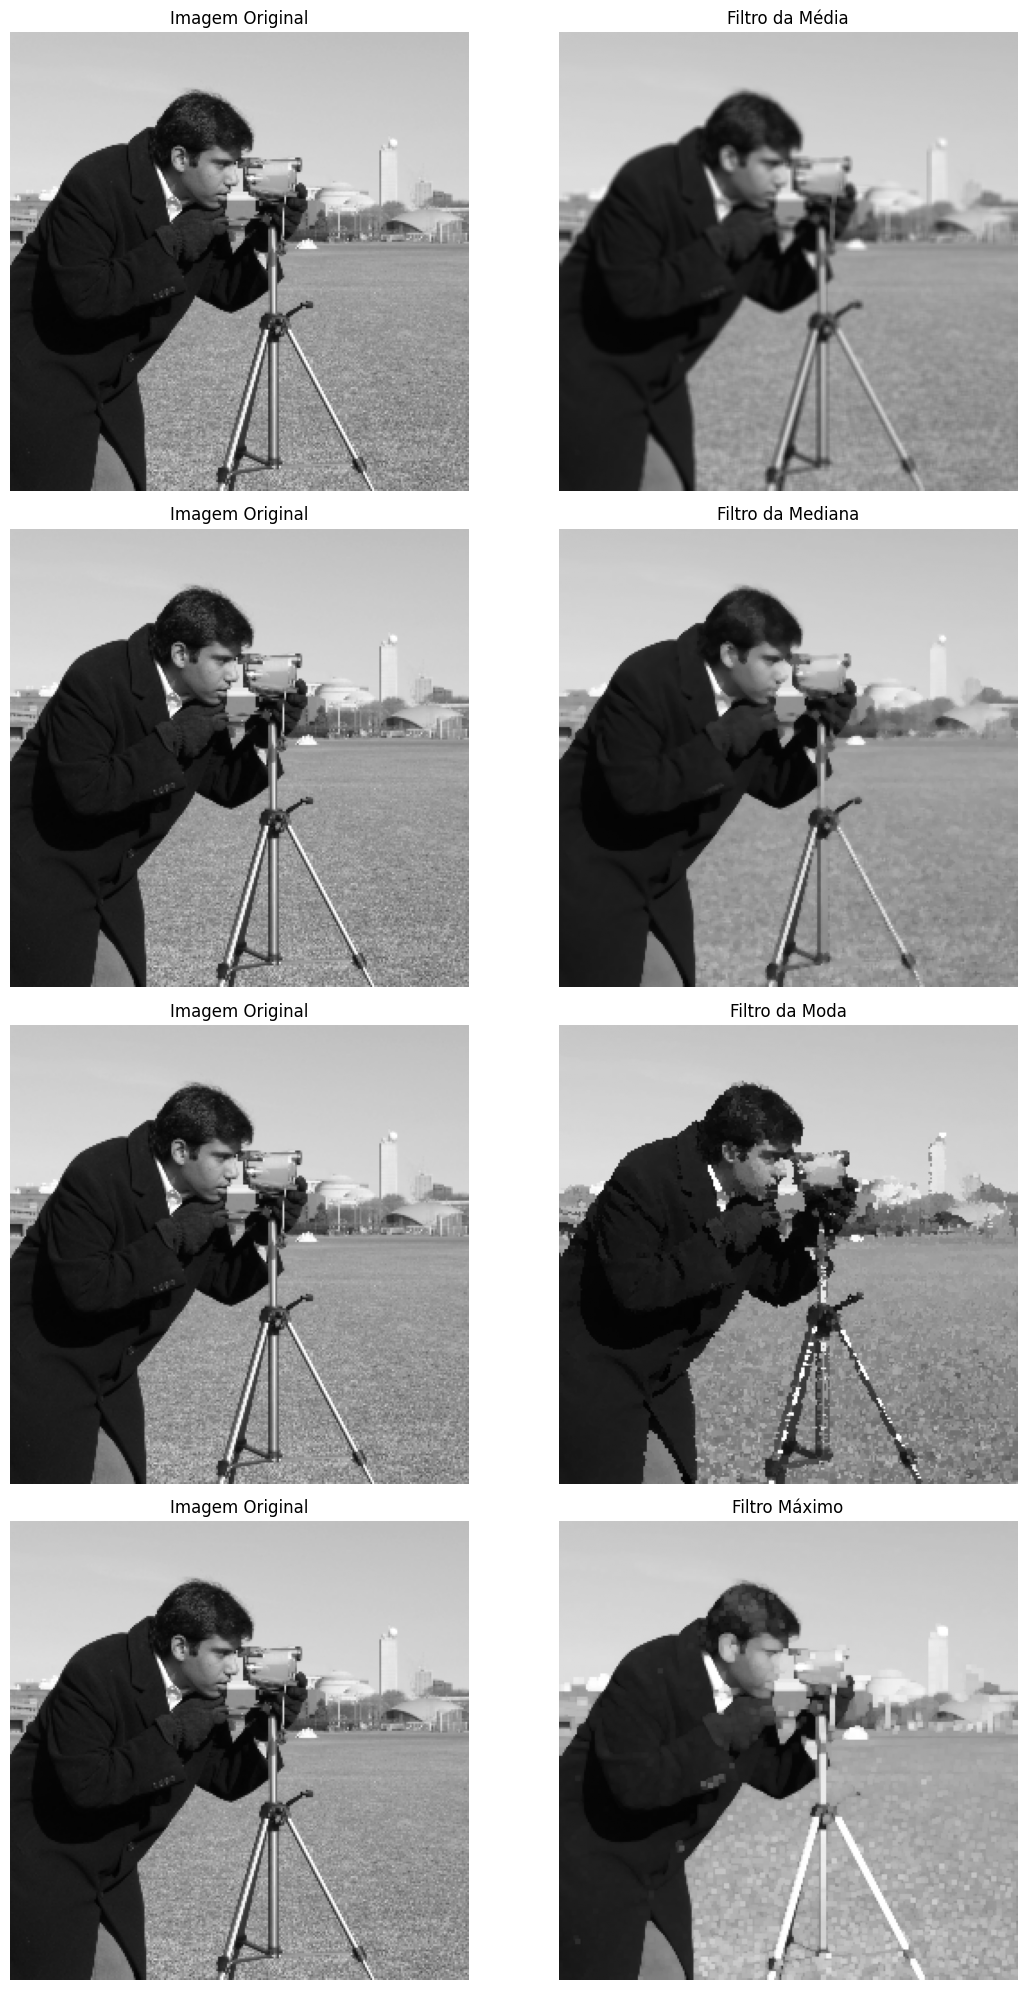

In [25]:
resultados = [
    ("Filtro da Média", imagem_media),
    ("Filtro da Mediana", imagem_mediana),
    ("Filtro da Moda", imagem_moda),
    ("Filtro Máximo", imagem_maximo)
]

fig, axes = plt.subplots(4, 2, figsize=(12, 20))

for i, (nome, imagem_filtrada) in enumerate(resultados):

    axes[i, 0].imshow(imagem, cmap='gray', vmin=0, vmax=255)
    axes[i, 0].set_title("Imagem Original")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(imagem_filtrada, cmap='gray', vmin=0, vmax=255)
    axes[i, 1].set_title(nome)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()